# Matplotlib Explained: Choosing the Right Plot and Creating Your First Visualizations

# Dataset and Blog

You can access the [Spotify dataset](https://www.kaggle.com/datasets/joebeachcapital/30000-spotify-songs) and read the complete Medium blog to learn more about Matplotlib and data visualization.

# Dataset Exploration

## Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Read Data

In [2]:
df = pd.read_csv("spotify_songs.csv")
df.shape

(32833, 23)

## Information About The Dataset

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  object 
 1   track_name                32828 non-null  object 
 2   track_artist              32828 non-null  object 
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  object 
 5   track_album_name          32828 non-null  object 
 6   track_album_release_date  32833 non-null  object 
 7   playlist_name             32833 non-null  object 
 8   playlist_id               32833 non-null  object 
 9   playlist_genre            32833 non-null  object 
 10  playlist_subgenre         32833 non-null  object 
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-null  int64  
 14  loudne

## Dataset Shape

In [4]:
df.dropna(inplace=True)
df.shape

(32828, 23)

## First 5 Rows

In [5]:
df.head()

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


# 1. What proportions of the songs belongs to the most common genre?

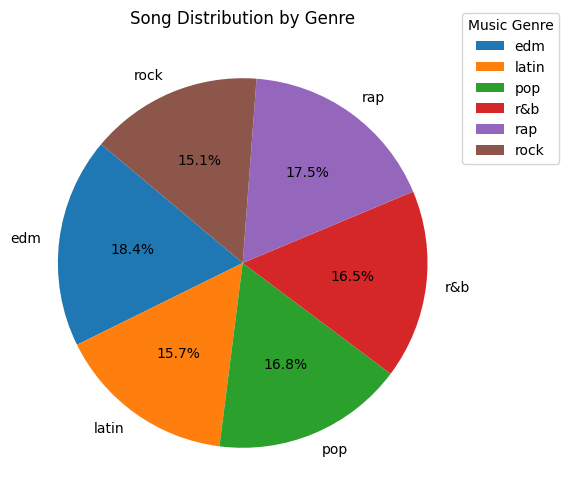

In [6]:
# Most common genre
genre_counts = df.groupby('playlist_genre')['track_id'].count()

plt.figure(figsize=(8, 6))
plt.pie(
    genre_counts,
    labels=genre_counts.index,
    autopct='%1.1f%%',
    startangle=140
)
plt.legend(
    bbox_to_anchor=(1.2,0.7),
    title='Music Genre',
    loc='lower right'
)
plt.title('Song Distribution by Genre')
plt.show()

The pie chart shows the proportion of songs across six genres. EDM accounts for the largest share at 18.4%, followed by rap at 17.5% and pop at 16.8%. Rock has the smallest share at 15.1%. Overall, the distribution is relatively balanced, with each genre representing between 15% and 18.5% of the songs.

# 2. How has the average duration of songs changed over the years?

In [7]:
# Song Durations Over Time
# Convert to datetime
df['release_date_parsed'] = pd.to_datetime(df['track_album_release_date'], errors='coerce')

# Get year info
df['release_year'] = df['release_date_parsed'].dt.year

# Average duration (mins) by year
yearly_duration = df.groupby('release_year')['duration_ms'].mean() / 1000 / 60

years = yearly_duration.index
average_duration = yearly_duration.values

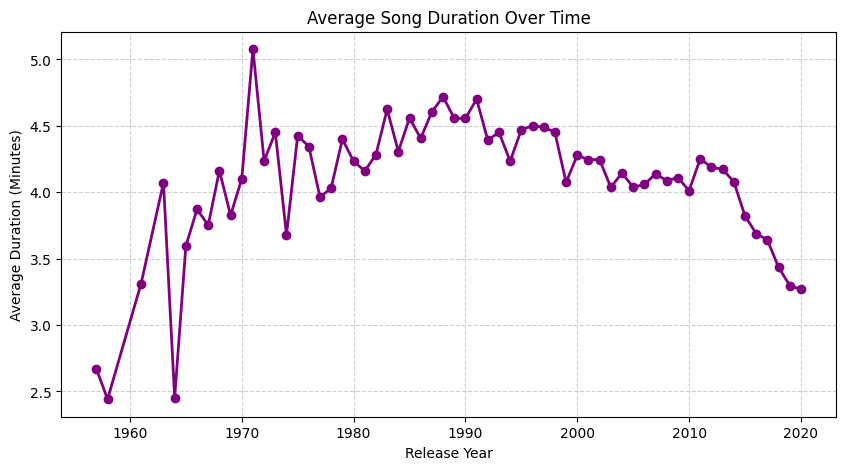

In [8]:
plt.figure(figsize=(10, 5))
plt.plot(
    years,
    average_duration,
    marker='o',
    color='purple',
    linestyle='-',
    linewidth=2
)
plt.title('Average Song Duration Over Time')
plt.xlabel('Release Year')
plt.ylabel('Average Duration (Minutes)')
plt.grid(
    True,
    linestyle='--',
    alpha=0.6
)
plt.show()

Average song duration increased through the 1960s, reaching its highest point in the early 1970s. Durations then fluctuated for several decades before declining noticeably after 2010.

# 3. How are song durations distributed?

In [9]:
# Average duration of songs
duration = df['duration_ms'].mean()
print("Average duration of songs is", round(duration/1000/60,2), "minutes.")

Average duration of songs is 3.76 minutes.


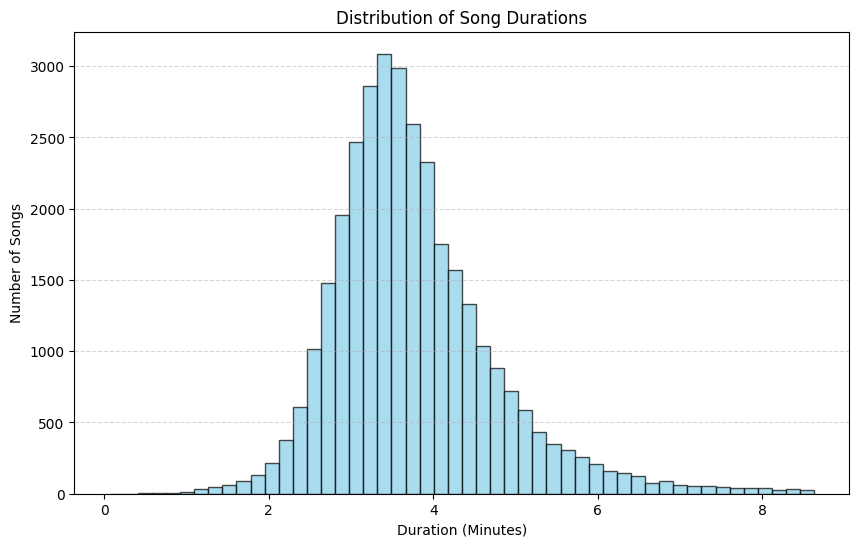

In [10]:
# Convert durations from milliseconds to minutes
duration_mins = df['duration_ms'] / 1000 / 60

plt.figure(figsize=(10, 6))
plt.hist(
    duration_mins,
    bins=50,
    color='skyblue',
    edgecolor='black',
    alpha=0.7
)
plt.title('Distribution of Song Durations')
plt.xlabel('Duration (Minutes)')
plt.ylabel('Number of Songs')
plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.5
)
plt.show()

Most songs last between 3 and 4 minutes, with the highest concentration around 3.5–3.7 minutes. The distribution is right-skewed, meaning that while longer songs are less common, a small number extend beyond 6 minutes.

# 4. Which genre has longest duration?

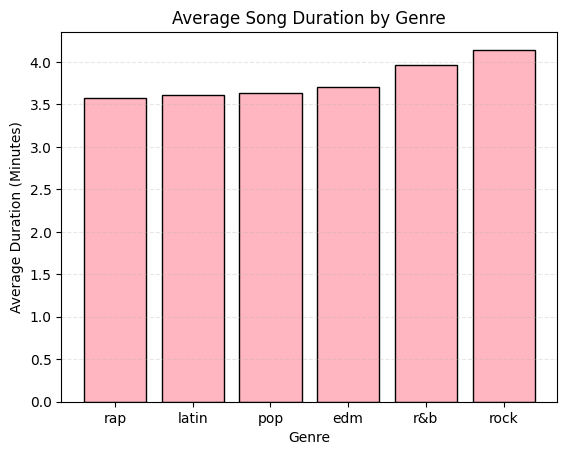

In [11]:
# Average Song Duration by Genre
avg_dur_by_genre = df.groupby('playlist_genre')['duration_ms'].mean().sort_values()

plt.bar(
    avg_dur_by_genre.index,
    avg_dur_by_genre.values/1000/60,
    color='lightpink',
    edgecolor='black'
)
plt.title('Average Song Duration by Genre')
plt.xlabel('Genre')
plt.ylabel('Average Duration (Minutes)')
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)
plt.show()

Rock has the highest average song duration, followed by R&B. Rap has the shortest average duration. Overall, average song durations are relatively similar across genres.

# 5. What is the most energetic genre?

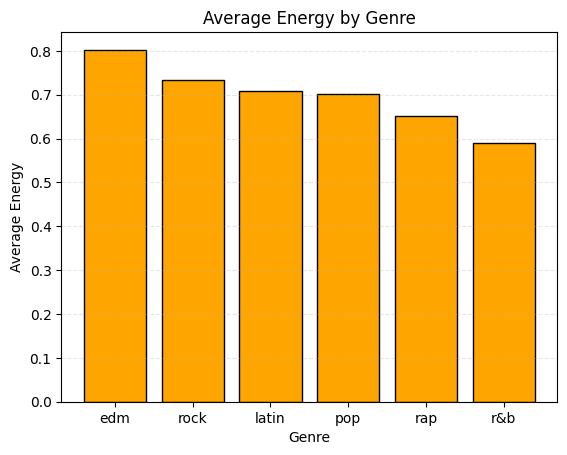

In [12]:
# Average Energy by Genre
genre_energy = df.groupby('playlist_genre')['energy'].mean().sort_values(ascending=False)

plt.bar(
    genre_energy.index,
    genre_energy.values,
    color='orange',
    edgecolor='black'
)
plt.title('Average Energy by Genre')
plt.xlabel('Genre')
plt.ylabel('Average Energy')
plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)
plt.show()

EDM has the highest average energy followed by rock. R&B has the lowest average energy.

# 6. Which genre has the most positive musical mood on average?

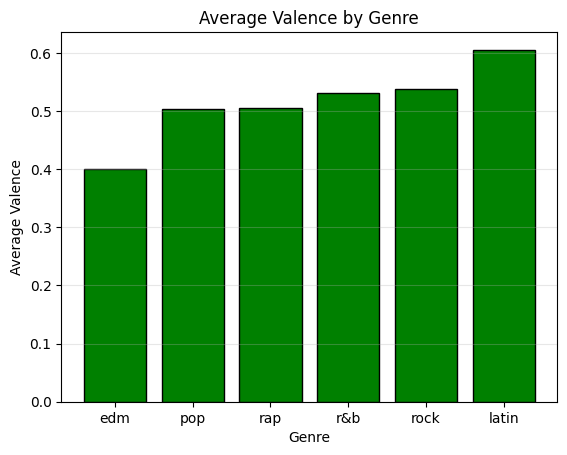

In [13]:
# Average Valence by Genre
avg_valence_by_genre = df.groupby('playlist_genre')['valence'].mean().sort_values()

plt.bar(
    avg_valence_by_genre.index,
    avg_valence_by_genre.values,
    color='green',
    edgecolor='black'
)
plt.title('Average Valence by Genre')
plt.xlabel('Genre')
plt.ylabel('Average Valence')
plt.grid(
    axis='y',
    alpha=0.3
)
plt.show()

Latin has the highest average valence suggesting a more positive or cheerful musical mood. EDM has the lowest average valence. The remaining genres fall in between indicating relatively similar average valence scores.

# 7. What is the most danceable genre?

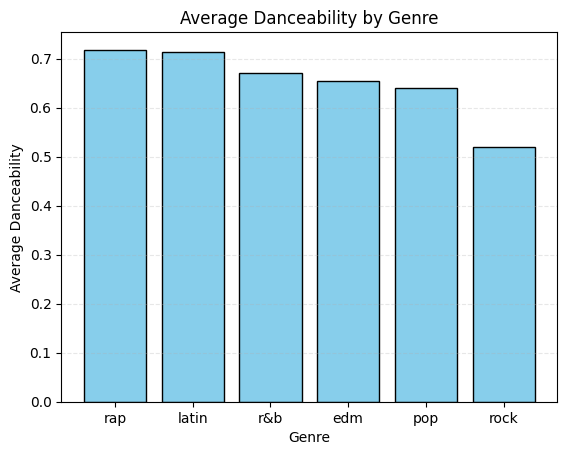

In [14]:
# Average Danceability by Genre
genre_danceability = df.groupby('playlist_genre')['danceability'].mean().sort_values(ascending=False)

plt.bar(
    genre_danceability.index,
    genre_danceability.values,
    color='skyblue',
    edgecolor='black'
)
plt.title('Average Danceability by Genre')
plt.xlabel('Genre')
plt.ylabel('Average Danceability')
plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)
plt.show()

Rap has the highest average danceability closely followed by Latin. Rock has the lowest average danceability. Overall, rap and Latin tracks tend to have higher danceability scores than the other genres.

# 8. Which genre uses the most amount of words?

In [15]:
# Average Speechiness by Genre
genre_speechiness = df.groupby('playlist_genre')['speechiness'].mean().sort_values()

genre = genre_speechiness.index
speechiness = genre_speechiness.values

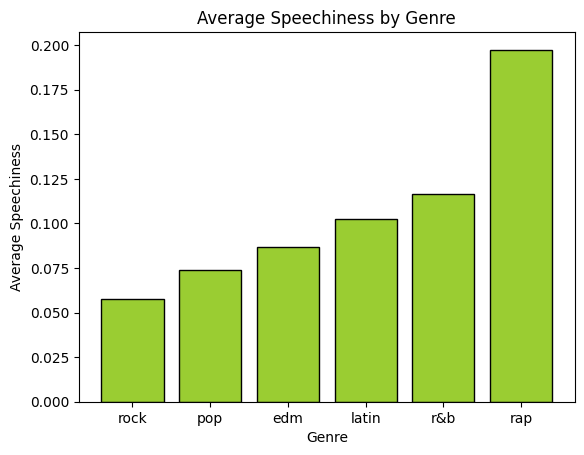

In [16]:
plt.bar(
    genre,
    speechiness,
    color='yellowgreen',
    edgecolor='black'
)
plt.title('Average Speechiness by Genre')
plt.xlabel('Genre')
plt.ylabel('Average Speechiness')
plt.show()

Rap has the highest average speechiness among the genres, followed by R&B and Latin. Rock has the lowest average speechiness, suggesting that rap tracks tend to contain more spoken-word elements than other genres.

# 9. Are more energetic songs more popular?

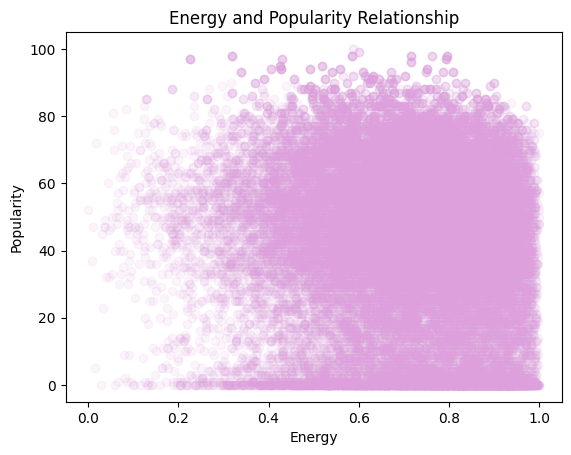

In [17]:
# Energy vs popularity
energy = df['energy']
popularity = df['track_popularity']

plt.scatter(
    energy,
    popularity,
    alpha=0.1,
    color='plum'
)
plt.title('Energy and Popularity Relationship')
plt.xlabel('Energy')
plt.ylabel('Popularity')
plt.show()

The scatter plot shows no clear relationship between song energy and popularity. Songs with a wide range of popularity scores appear across different energy levels, suggesting that higher energy does not necessarily translate into greater popularity.

In [18]:
corr = energy.corr(popularity)
print("Correlation coefficient between energy and popularity: ", round(corr,2))

Correlation coefficient between energy and popularity:  -0.11


Energy and popularity are slight negativly correlated. So we cannot say that more energetic songs are more popular.

# 10. How does song popularity vary across different genres?

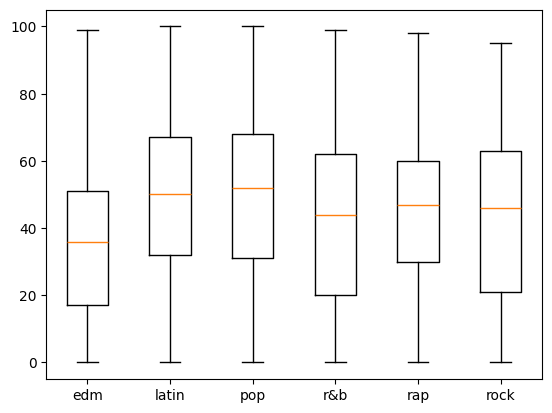

In [19]:
# Popularity Across Genres
all_genres = sorted(df["playlist_genre"].unique())
data_groups = [
    df[df["playlist_genre"] == genre]["track_popularity"]
    for genre in all_genres
]

plt.boxplot(
    data_groups,
    tick_labels=all_genres
)
plt.show()

Pop has the highest median popularity, followed closely by Latin. EDM has the lowest median. The wide boxes and whiskers across genres indicate substantial variation in song popularity within each genre.